# Do the significant non-SNP variants change repeats -- and do they touch LEA / ELIP?

Structural and indel variation is concentrated in repetitive sequence, and repetitive sequence can
be functional: repeat-encoded protein segments (the dehydrin K-segments and the LEA_4 11-mer
repeats are the classic plant cases), polyQ / polyS tracts, repeated ubiquitin units, microsatellites
in promoters and UTRs. Two questions, from `build_repeat_variants.py`:

1. **Which significant non-SNP variants add or remove copies of a tandem repeat unit, where, and is
   that more common among the hits than among all testable variants?**
2. **Does any significant variant sit in or near an LEA or ELIP gene?**

**Repeat-copy call.** For every panel record at a pooled SV / small-indel hit (MNPs excluded), the
changed segment is ALT vs REF with the shared prefix/suffix trimmed. It is a *repeat-copy change*
when it matches the TAIR10 bases immediately beside it at >= 90% identity (allowing the unit to be
phased differently from the flank). The unit is the segment's smallest internal period. A 1 bp
indel in a homopolymer is a repeat-copy change with a 1 bp unit; a 60 bp insertion that repeats the
adjacent 60 bp is one with a 60 bp unit.

**Background.** Every panel indel / SV locus with seed-mix (p0) minor-allele frequency > 0.05
(~480k loci) -- an approximation of the testable set -- called the same way. 2,105 of the 2,468 hit
loci are in that set (the rest are GWAS-only rare variants, or GEA hits whose p0 MAF is <= 0.05 --
the GEA filtered on its own MAF, which correlates with p0 MAF at r ~ 0.7-0.9). The comparison uses
those 2,105, minus loci whose every record is a complex (non-anchored) change, so both sides share
one universe. **Both sides are collapsed to loci with the same rule**: a locus is a repeat-copy
change if any of its records is.

**Site effects** use every TAIR10 transcript (most severe shown); in-CDS for the comparison means
the first changed base lies in any transcript's CDS.

In [1]:
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import fisher_exact
plt.rcParams.update({'figure.dpi':110,'font.size':8,'axes.linewidth':0.6})
pd.set_option("display.width", 320); pd.set_option("display.max_colwidth", 200); pd.set_option("display.max_rows", 300)
R = os.path.abspath("../genes/convergence/results")
K4 = ["chrom","pos","ref_len","alt_len"]

L = pd.read_csv(f"{R}/repeat_variants_loci.csv", keep_default_na=False)
for c in ["gea_nlp","unit_len","n_units_changed","size","seg_len"]:
    L[c] = pd.to_numeric(L[c], errors="coerce")
L["maf"] = pd.to_numeric(L.maf, errors="coerce")
for c in ["repeat_copy_change","in_cds","in_background","inframe","in_gea","in_gwas","all_complex"]:
    L[c] = L[c].astype(str).eq("True")
B = pd.read_csv(f"{R}/repeat_variants_background_v2.csv.gz",
                usecols=K4 + ["kind","unit_len","repeat_copy_change","in_cds","size","vclass","maf"])
B["repeat_copy_change"] = B.repeat_copy_change.astype(str).eq("True")
B["in_cds"] = B.in_cds.astype(str).eq("True")
B["_cx"] = B.kind.astype(str).str.startswith("complex")
g = B.groupby(K4, sort=False)                       # one row per locus, same rule as the hits
B = g.first().reset_index().assign(repeat_copy_change=g.repeat_copy_change.any().values,
                                   all_complex=g._cx.all().values, maf=g.maf.max().values)
B["inframe"] = B["size"] % 3 == 0
GA = pd.read_csv(f"{R}/repeat_variants_genes.csv", keep_default_na=False)
pname = {g: (p or t or m) for g, p, t, m in zip(GA.gene, GA.protein_name, GA.tair_name, GA.mygene_name)}

H = L[L.in_background & ~L.all_complex].copy()
Bb = B[~B.all_complex].copy()
print(f"hit loci: {len(L):,} ({(L.vclass=='sv').sum()} SV, {(L.vclass=='smallindel').sum():,} small indel); "
      f"in the testable set and not complex: {len(H):,}")
print(f"background loci (testable, not complex): {len(Bb):,}")

def style(ax, axis="both"):
    ax.set_axisbelow(True); ax.grid(color="0.88", lw=0.7, axis=axis)
    for sp in ax.spines.values(): sp.set_visible(False)
def pfmt(p): return f"{p:.1e}" if p < 1e-3 else f"{p:.2f}"


hit loci: 2,468 (367 SV, 2,101 small indel); in the testable set and not complex: 1,862
background loci (testable, not complex): 483,256


## 1. Are repeat-copy changes enriched among the hits?

Share of loci that are repeat-copy changes, hits vs testable background, within strata. **Do not
quote the "all variants" row**: it mixes classes -- SVs are ~13% of the hits but ~4% of the
background and are rarely repeat-copy changes -- so it shows an apparent depletion that is pure
composition (Simpson's paradox). The within-class rows, and the MAF-matched test below, are the
test.

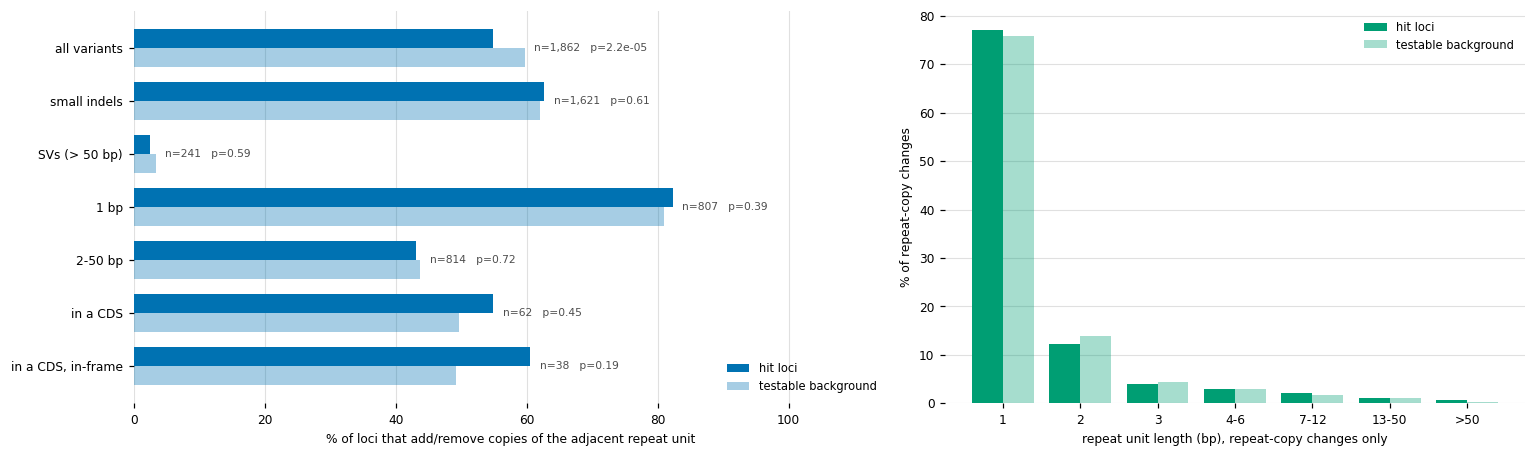

           stratum  hits  hit_rep  hit_pct     bg  bg_rep  bg_pct  fisher_p
      all variants  1862     1021   54.834 483256  288461  59.691     0.000
      small indels  1621     1015   62.616 464473  287832  61.970     0.608
     SVs (> 50 bp)   241        6    2.490  18783     629   3.349     0.588
              1 bp   807      664   82.280 226818  183755  81.014     0.393
           2-50 bp   814      351   43.120 237655  104077  43.793     0.723
          in a CDS    62       34   54.839  14326    7106  49.602     0.446
in a CDS, in-frame    38       23   60.526   8189    4029  49.200     0.194


In [2]:
STRATA = [("all variants", slice(None), slice(None)),
          ("small indels", H.vclass=="smallindel", Bb.vclass=="smallindel"),
          ("SVs (> 50 bp)", H.vclass=="sv", Bb.vclass=="sv"),
          ("1 bp", H["size"]==1, Bb["size"]==1),
          ("2-50 bp", H["size"].between(2,50), Bb["size"].between(2,50)),
          ("in a CDS", H.in_cds, Bb.in_cds),
          ("in a CDS, in-frame", H.in_cds & H.inframe, Bb.in_cds & Bb.inframe)]
rows = []
for lab, hm, bm in STRATA:
    h, b = H[hm], Bb[bm]
    a, c = int(h.repeat_copy_change.sum()), int(b.repeat_copy_change.sum())
    rows.append(dict(stratum=lab, hits=len(h), hit_rep=a, hit_pct=100*a/len(h), bg=len(b), bg_rep=c,
                     bg_pct=100*c/len(b), fisher_p=fisher_exact([[a, len(h)-a],[c, len(b)-c]])[1]))
T = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios":[1.3,1]})
style(ax[0], axis="x")
y = np.arange(len(T))[::-1]; w = 0.36
ax[0].barh(y + w/2, T.hit_pct, w, color="#0072B2", linewidth=0, label="hit loci")
ax[0].barh(y - w/2, T.bg_pct, w, color="#0072B2", alpha=0.35, linewidth=0, label="testable background")
for yi, r in zip(y, T.itertuples()):
    ax[0].text(max(r.hit_pct, r.bg_pct) + 1.5, yi, f"n={r.hits:,}   p={pfmt(r.fisher_p)}", va="center", fontsize=7, color="0.3")
ax[0].set_yticks(y); ax[0].set_yticklabels(T.stratum); ax[0].set_xlim(0, 115)
ax[0].set_xlabel("% of loci that add/remove copies of the adjacent repeat unit")
ax[0].legend(frameon=False, fontsize=7.5, loc="lower right")

style(ax[1], axis="y")
bins = [0, 1, 2, 3, 6, 12, 50, 1e6]; labs = ["1", "2", "3", "4-6", "7-12", "13-50", ">50"]
hc = pd.cut(H.loc[H.repeat_copy_change, "unit_len"], bins, labels=labs).value_counts(normalize=True).reindex(labs)
bc = pd.cut(Bb.loc[Bb.repeat_copy_change, "unit_len"], bins, labels=labs).value_counts(normalize=True).reindex(labs)
x = np.arange(len(labs))
ax[1].bar(x - 0.2, 100*hc, 0.4, color="#009E73", linewidth=0, label="hit loci")
ax[1].bar(x + 0.2, 100*bc, 0.4, color="#009E73", alpha=0.35, linewidth=0, label="testable background")
ax[1].set_xticks(x); ax[1].set_xticklabels(labs); ax[1].set_xlabel("repeat unit length (bp), repeat-copy changes only")
ax[1].set_ylabel("% of repeat-copy changes"); ax[1].legend(frameon=False, fontsize=7.5)
fig.tight_layout(); plt.show()
print(T.round(3).to_string(index=False))


### 1b. Matched on minor-allele frequency

GEA power depends on MAF, and hits sit at slightly higher MAF than the background. Cochran-Mantel-
Haenszel test stratified on size class (1 bp / 2-50 bp / SV) x MAF decile, background with the hits
removed. Seven subsets are tested, so a single p near 0.05 is not a finding.

In [3]:
from scipy.stats import chi2
Bo = Bb[~Bb.set_index(K4).index.isin(H.set_index(K4).index)].copy()
edges = np.quantile(Bo.maf.dropna(), np.linspace(0, 1, 11)[1:-1])
for df in (H, Bo):
    df["sizecls"] = np.select([df["size"] == 1, df["size"] <= 50], ["1bp", "2-50bp"], "SV")
    df["stratum"] = df.sizecls + "|" + np.searchsorted(edges, df.maf.fillna(0)).astype(str)
def cmh(h, b):
    num = den = sa = se = sv = 0.0
    for k, hh in h.groupby("stratum"):
        bb = b[b.stratum == k]
        a_, b_ = hh.repeat_copy_change.sum(), (~hh.repeat_copy_change).sum()
        c_, d_ = bb.repeat_copy_change.sum(), (~bb.repeat_copy_change).sum()
        n = a_ + b_ + c_ + d_
        if n < 2 or (a_ + b_) == 0 or (c_ + d_) == 0: continue
        num += a_ * d_ / n; den += b_ * c_ / n
        m1, n1 = a_ + c_, a_ + b_
        sa += a_; se += n1 * m1 / n; sv += n1 * (n - n1) * m1 * (n - m1) / (n * n * (n - 1))
    stat = (abs(sa - se) - 0.5) ** 2 / sv if sv else np.nan
    return dict(hits=len(h), observed=int(sa), expected=round(se, 1), OR_MH=round(num / den, 2) if den else np.nan,
                p=chi2.sf(stat, 1) if sv else np.nan)
rows = []
for lab, hm in [("all (size x MAF strata)", slice(None)), ("1 bp", H.sizecls == "1bp"), ("2-50 bp", H.sizecls == "2-50bp"),
                ("SV", H.sizecls == "SV"), ("in a CDS", H.in_cds), ("in a CDS, in-frame", H.in_cds & H.inframe)]:
    h = H[hm]; bm = Bo.in_cds if "CDS" in lab else slice(None)
    if "in-frame" in lab: bm = Bo.in_cds & Bo.inframe
    rows.append(dict(subset=lab, **cmh(h, Bo[bm])))
print(pd.DataFrame(rows).assign(p=lambda d: d.p.map(pfmt)).to_string(index=False))
print(f"\nmedian MAF: hits {H.maf.median():.3f}, background {Bo.maf.median():.3f}")


                 subset  hits  observed  expected  OR_MH    p
all (size x MAF strata)  1862      1021    1018.2   1.01 0.90
                   1 bp   807       664     654.3   1.08 0.41
                2-50 bp   814       351     355.6   0.98 0.77
                     SV   241         6       8.3   0.71 0.52
               in a CDS    62        34      27.0   1.81 0.07
     in a CDS, in-frame    38        23      17.6   1.91 0.10

median MAF: hits 0.157, background 0.147


## 2. Repeat-copy changes inside coding sequences

The cases where a repeat-encoded stretch of a protein gets longer or shorter (in-frame), or where a
homopolymer / microsatellite step shifts the frame. For each: the repeat unit, how many units are
gained or lost, the protein around the change (reference, then variant), and the gene.

In [4]:
C = L[L.repeat_copy_change & L.site_feature.str.startswith("CDS")].copy()
C["gene_name"] = C.site_effect_gene.map(lambda g: pname.get(g, "?"))
C["dir"] = np.where(C.kind.str.contains("insertion"), "+", "-")
C["units"] = C["dir"] + C.n_units_changed.map(lambda v: f"{v:g}") + " x " + C.unit.str[:30]
C = C.sort_values(["site_feature","gea_nlp"], ascending=[True, False])
print(C.site_feature.value_counts().to_string()); print()
for r in C.itertuples():
    test = f"GEA -log10p {r.gea_nlp:.1f} ({r.gea_best_axis})" if np.isfinite(r.gea_nlp) else "GWAS-only"
    print(f"{r.chrom}:{r.pos:,}  {r.vclass}  {test}")
    print(f"   {r.site_effect_gene} [{r.gene_name}]  {r.site_tx}")
    print(f"   unit change : {r.units} (unit {int(r.unit_len)} bp; {r.ref_copies_right} more copies in the reference flank)")
    print(f"   effect      : {r.protein_effect}")
    if r.wt_context: print(f"   protein ref : {r.wt_context}\n   protein var : {r.mut_context}")
    print()


site_feature
CDS:truncating    22
CDS:in-frame      14
CDS:synonymous     3
CDS:frameshift     2

Chr3:11,785,034  smallindel  GEA -log10p 8.6 (bio15)
   AT3G30160 [Transmembrane protein]  AT3G30160.1
   unit change : -1 x G (unit 1 bp; 2 more copies in the reference flank)
   effect      : frameshift; C-terminus replaced, 91 -> 91 aa
   protein ref : NSSGGIGDPFPVTSEGVWRVL
   protein var : NSSGGIGDPFPSRPKEFGEFL

Chr4:6,984,052  smallindel  GEA -log10p 7.4 (bio6)
   AT4G11510 [Protein RALF-like 28]  AT4G11510.1
   unit change : +1 x A (unit 1 bp; 1 more copies in the reference flank)
   effect      : frameshift; C-terminus replaced, 85 -> 86 aa
   protein ref : DPPALPRKMI
   protein var : DPPALPRKMIL

Chr5:5,823,011  smallindel  GEA -log10p 9.5 (bio15)
   AT5G17680 [ADP-ribosyl cyclase/cyclic ADP-ribose hydrolase (EC 3.2.2.6)]  AT5G17680.1
   unit change : +7 x CTT (unit 3 bp; 8 more copies in the reference flank)
   effect      : in-frame +7 aa, no new stop (1294 -> 1301 aa)
   protein

## 3. Repeat-copy changes in UTRs, introns and promoters

Non-coding repeat steps near genes (tier = promoter for upstream loci). Counts by feature, then the
loci whose unit is longer than 2 bp (the homopolymer / dinucleotide steps are listed in the CSV).

In [5]:
N = L[L.repeat_copy_change & ~L.site_feature.str.startswith("CDS")].copy()
N["where"] = np.where(N.site_feature != "", N.site_feature, N.tier)
print(N["where"].value_counts().to_string()); print()
N["gene_name"] = N.site_effect_gene.map(lambda g: pname.get(g, "") if g else "")
M = N[N.unit_len > 2].sort_values("gea_nlp", ascending=False)
print(f"{len(M)} non-coding repeat-copy changes with a unit > 2 bp:")
print(M[["chrom","pos","vclass","kind","unit_len","n_units_changed","unit","where","site_effect_gene","gene_name","nearest_gene","dist_to_gene","gea_nlp"]]
      .assign(unit=lambda d: d.unit.str[:30], gene_name=lambda d: d.gene_name.str[:50]).round(2).to_string(index=False))


where
3_promoter               317
7_proximal_intergenic    268
intron                   236
6_TE                     172
3'UTR                     57
exon(non-coding)          53
5'UTR                     37
splice-region             21
8_gene_desert             11
gene(no transcript)        5

102 non-coding repeat-copy changes with a unit > 2 bp:
chrom      pos     vclass               kind  unit_len  n_units_changed                           unit                 where site_effect_gene                                          gene_name nearest_gene  dist_to_gene  gea_nlp
 Chr2 12138565 smallindel           deletion         3              1.0                            ATT 7_proximal_intergenic                                                                        AT2G28390          1012    15.47
 Chr5 21036908 smallindel          insertion         4              1.0                           ATTA                  6_TE                                                                  

## 4. LEA and ELIP

The gene set is the 59-gene list used by the earlier LEA/ELIP analyses
(`arabidopsismaster/data/LEA_ELIP_genes_arabidopsis.tsv`, recovered from
`lea_elip_sv/lea_elip.flank2kb.bed` on Drive; copy in `results/lea_elip_ref/`): the 51 LEA genes of
Hundertmark & Hincha (2008) and 8 ELIP-family genes. The cell-type report's 57-gene universe is this
list minus SEP1 and SEP2 (`in_57`). Every significant variant (small indels, MNPs, SVs) within 2 kb
of any of the 59 genes is listed, with its distance to the gene body and the strand-aware position
relative to the LEA/ELIP gene.

In [6]:
G = pd.read_csv(f"{R}/lea_elip_genes.csv", keep_default_na=False)
print(G.groupby(["family", "in_57"]).size().to_string()); print()
LE = pd.read_csv(f"{R}/lea_elip_hits.csv", keep_default_na=False)
LE["pos"] = LE.pos.astype(int)
GG = G.set_index("gene")
def rel(r):
    g = GG.loc[r.gene]; s, e = int(g.start), int(g.end)
    if s <= r.pos <= e: return "inside gene"
    up = (r.pos < s) if g.strand == "+" else (r.pos > e)
    return ("upstream (5')" if up else "downstream (3')") + f", {r.dist} bp"
LE["relative_to_LEA_ELIP_gene"] = [rel(r) for r in LE.itertuples()]
print(f"significant variants within 2 kb of an LEA/ELIP gene: {len(LE)} at {LE.gene.nunique()} genes "
      f"({LE[LE.in_57.astype(str)=='True'].gene.nunique()} of them in the 57-gene universe)")
print(LE[["gene","name","in_57","chrom","pos","vclass","ref_len","alt_len","relative_to_LEA_ELIP_gene","tier",
          "in_gea","in_gwas","gea_nlp","gea_best_axis","repeat_copy_change","site_feature"]].to_string(index=False))
print(f"\nLEA/ELIP genes with no significant variant within 2 kb: {len(G) - LE.gene.nunique()} of {len(G)}")


family  in_57
ELIP    False     2
        True      6
LEA     True     51



significant variants within 2 kb of an LEA/ELIP gene: 7 at 4 genes (3 of them in the 57-gene universe)
     gene               name  in_57 chrom      pos     vclass  ref_len  alt_len relative_to_LEA_ELIP_gene                  tier  in_gea  in_gwas           gea_nlp gea_best_axis repeat_copy_change site_feature
AT3G22840              ELIP1   True  Chr3  8084255 smallindel        1        2   downstream (3'), 192 bp 7_proximal_intergenic   False     True                                               True             
AT4G13230 LEA domain protein   True  Chr4  7675519 smallindel        1        3   downstream (3'), 134 bp            3_promoter    True    False 7.610166320979518          bio8              False             
AT4G13230 LEA domain protein   True  Chr4  7675522 smallindel        1        4   downstream (3'), 131 bp            3_promoter    True    False 7.731337193511574          bio8              False             
AT4G34190          SEP1/LIL4  False  Chr4 16374844 smallindel

## 5. What this says

- **Repeat-copy variation is common among the hits, but no more common than among any testable
  variant.** Within every class and size stratum the hit share matches the background (small indels
  63% vs 62%, SVs 2% vs 3%, 1 bp 82% vs 81%, 2-50 bp 43% vs 44%), and the MAF-matched
  Mantel-Haenszel test agrees (overall OR 1.01, p = 0.90). The pooled "all variants" row is a
  class-mix artefact and should not be quoted.
- **Coding sequence is the one place worth watching, not a finding.** Hits in a CDS are a little more
  often repeat-copy changes (matched OR 1.8, p = 0.07; in-frame OR 1.9, p = 0.10), on 62 and 38 loci,
  among seven subsets tested.
- **The coding repeat changes are concrete** and several are the kind of repeat-encoded protein
  segment the question is about: one extra ubiquitin unit in UBQ3, two extra 10-aa
  `VSKVETLDDC`-type motifs (+20 aa) in PHOX3, homopeptide tracts changing length -- polyglutamate
  E6 -> E5 in AT4G08550 (the strongest, -log10 p 12.3), polyglutamine Q4 -> Q3 in CORD6 (AT3G19610)
  and Q6 -> Q3 in AT2G26920, polyserine S8 -> S15 in AT5G17680 -- plus single-codon steps in other
  genes and homopolymer frameshifts. Each is only as solid as its panel call: PHOX3 is a GWAS-only,
  low-MAC hit.
- **LEA / ELIP: very little, and the test is narrow.** Only the Bonferroni non-SNP pool was looked
  at (small indels, MNPs, SVs -- no SNPs). Of the 59 genes, 4 have a significant variant within 2 kb
  and none has one in the gene body; 3 of the 4 are in the 57-gene universe. Of those, **AT4G13230**
  (LEA) has two adjacent small insertions ~130 bp beyond its 3' end -- also the promoter of the
  neighbouring AT4G13220 -- (bio8, -log10 p 7.6-7.7); **OHP1** has a 1 bp homopolymer step 155 bp
  upstream (bio15), while its two MNPs ~1 kb downstream sit in a neighbouring gene's intron; the
  **ELIP1** variant is GWAS-only (one garden). The SEP1 variant (outside the 57) is in an intron of
  AT4G34200. None of the named dehydrins (COR47, ERD10, ERD14, RAB18, XERO1/2) or COR15A/B has a
  significant variant nearby. A fairer test of the families would be a gene-set test on the raw
  GEA statistics, SNPs included, against size- and MAF-matched gene sets -- not done here.

**Caveats.** The testable set is approximated by seed-mix (p0) MAF > 0.05 (the GEA filtered on its
own MAF). The repeat call is a flank-identity rule, not a full tandem-repeat finder; long, diverged
repeat arrays are under-called. The multi-record loci are collapsed with the same any-record rule on
both sides.